### RNN with Attention (Possible solution)

In [1]:
# -*- coding: utf-8 -*-
"""
Wind Turbine Power Prediction with RNNs + Attention

This lab uses an Attention-enhanced Recurrent Neural Network to predict wind turbine power output.
"""

# Step 0: Load libraries & Data
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error, r2_score
import tensorflow as tf
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input, LSTM, Dense, Dropout, Layer
from tensorflow.keras.callbacks import EarlyStopping
import math

# Set random seeds for reproducibility
np.random.seed(42)
tf.random.set_seed(42)



2026-10-13 16:40:49.018999: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


In [2]:
# Step 1: Prepare the Data

# Load the data
df = pd.read_csv('T1.csv')
df['Date/Time'] = pd.to_datetime(df['Date/Time'], format='%d %m %Y %H:%M') # Convert date/time to a proper format
print(df.isnull().sum()) # Check for missing values
df.describe()

Date/Time                        0
LV ActivePower (kW)              0
Wind Speed (m/s)                 0
Theoretical_Power_Curve (KWh)    0
Wind Direction (°)               0
dtype: int64


,Date/Time,LV ActivePower (kW),Wind Speed (m/s),Theoretical_Power_Curve (KWh),Wind Direction (°)
count,50530,50530.000000,50530.000000,50530.000000,50530.000000
mean,2018-07-01 20:01:30.065307648,1307.684332,7.557952,1492.175463,123.687559
min,2018-01-01 00:00:00,-2.471405,0.000000,0.000000,0.000000
25%,2018-04-03 05:22:30,50.677890,4.201395,161.328167,49.315437
50%,2018-06-30 16:15:00,825.838074,7.104594,1063.776283,73.712978
75%,2018-09-26 18:57:30,2482.507568,10.300020,2964.972462,201.696720
max,2018-12-31 23:50:00,3618.732910,25.206011,3600.000000,359.997589
std,NaN,1312.459242,4.227166,1368.018238,93.443736


In [3]:
df.columns

Index(['Date/Time', 'LV ActivePower (kW)', 'Wind Speed (m/s)',
       'Theoretical_Power_Curve (KWh)', 'Wind Direction (°)'],
      dtype='object')

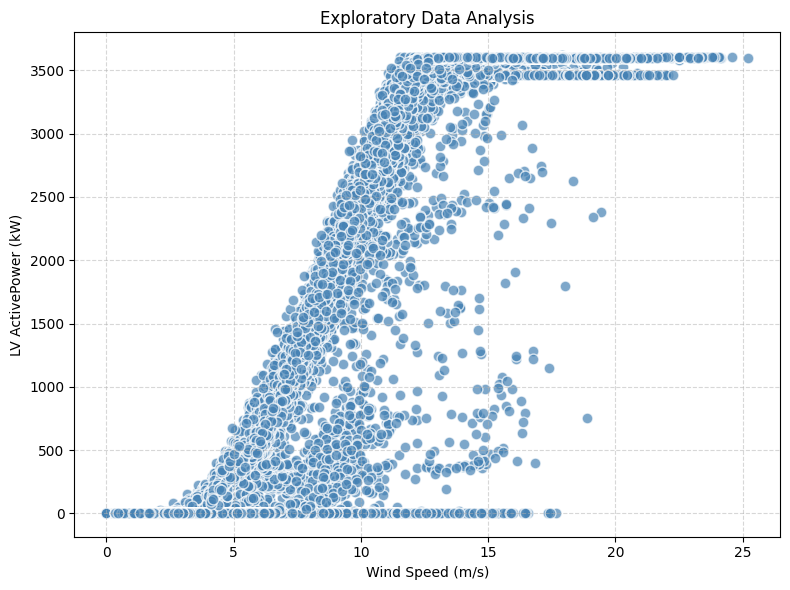

In [4]:
#scatter plots - Wind Speed vs. Active Power

x = df['Wind Speed (m/s)']
y = df['LV ActivePower (kW)']

# scatter plot
plt.figure(figsize=(8,6))
plt.scatter(x, y, alpha=0.7, c='steelblue', edgecolors='white', s=60)

plt.xlabel('Wind Speed (m/s)')
plt.ylabel('LV ActivePower (kW)')
plt.title('Exploratory Data Analysis')
plt.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()


In [5]:
# select and normalize features

features = ['LV ActivePower (kW)', 'Wind Speed (m/s)', 'Theoretical_Power_Curve (KWh)']
data = df[features]

scaler = MinMaxScaler(feature_range=(0, 1))
scaled_data = scaler.fit_transform(data)


In [6]:
# Step 2: Create sequences

def create_sequences(scaled_data, seq_length):
    X, y = [], []
    for i in range( len(scaled_data) - seq_length ):
        X.append(scaled_data[i:i + seq_length])
        y.append(scaled_data[i + seq_length, 0])  # only Active Power
    return np.array(X), np.array(y)

seq_length = 24
X, y = create_sequences(scaled_data, seq_length)
X.shape, y.shape

((50506, 24, 3), (50506,))

In [7]:
# Step 3: Split the data

train_size = int(len(X) * 0.8)

X_train, X_test = X[:train_size], X[train_size:]

y_train, y_test = y[:train_size], y[train_size:]

X_train.shape, X_test.shape, y_train.shape, y_test.shape 

((40404, 24, 3), (10102, 24, 3), (40404,), (10102,))

In [8]:
# Step 4: Define a Custom Attention Layer

class AttentionLayer(Layer):
    def __init__(self, **kwargs):
        super(AttentionLayer, self).__init__(**kwargs)

    def build(self, input_shape):
        self.W = self.add_weight(name="att_weight", shape=(input_shape[-1], input_shape[-1]), initializer="normal")
        self.b = self.add_weight(name="att_bias", shape=(input_shape[-1],), initializer="zeros")
        super(AttentionLayer, self).build(input_shape)

    def call(self, inputs):
        score = tf.tanh(tf.matmul(inputs, self.W) + self.b)
        attention_weights = tf.nn.softmax(score, axis=1)
        context_vector = attention_weights * inputs
        context_vector = tf.reduce_sum(context_vector, axis=1)
        return context_vector, attention_weights



In [9]:
# Step 5: Build the RNN Model with Attention

input_seq = Input(shape=(seq_length, 3))  # 3 features

lstm_out1 = LSTM(50, return_sequences=True)(input_seq)
drop1 = Dropout(0.2)(lstm_out1)

lstm_out2 = LSTM(50, return_sequences=True)(drop1)
drop2 = Dropout(0.2)(lstm_out2)

context_vector, attention_weights = AttentionLayer()(drop2)
output = Dense(1, activation='linear')(context_vector)

model = Model(inputs=input_seq, outputs=output)

model.summary()


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 24, 3)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, 24, 50)         │        10,800 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 24, 50)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 24, 50)         │        20,200 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 24, 50)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ attention_layer                 │ [(None, 50), (None,    │         2,550 │
│ (AttentionLayer)                │ 24, 50)]               │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │            51 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 33,601 (131.25 KB)

 Trainable params: 33,601 (131.25 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/30
1011/1011 ━━━━━━━━━━━━━━━━━━━━ 15s 12ms/step - loss: 0.0209 - val_loss: 0.0066
Epoch 2/30
1011/1011 ━━━━━━━━━━━━━━━━━━━━ 14s 13ms/step - loss: 0.0093 - val_loss: 0.0047
Epoch 3/30
1011/1011 ━━━━━━━━━━━━━━━━━━━━ 13s 13ms/step - loss: 0.0071 - val_loss: 0.0046
Epoch 4/30
1011/1011 ━━━━━━━━━━━━━━━━━━━━ 14s 14ms/step - loss: 0.0066 - val_loss: 0.0045
Epoch 5/30
1011/1011 ━━━━━━━━━━━━━━━━━━━━ 13s 13ms/step - loss: 0.0063 - val_loss: 0.0049
Epoch 6/30
1011/1011 ━━━━━━━━━━━━━━━━━━━━ 12s 12ms/step - loss: 0.0060 - val_loss: 0.0043
Epoch 7/30
1011/1011 ━━━━━━━━━━━━━━━━━━━━ 14s 13ms/step - loss: 0.0059 - val_loss: 0.0046
Epoch 8/30
1011/1011 ━━━━━━━━━━━━━━━━━━━━ 13s 13ms/step - loss: 0.0058 - val_loss: 0.0047
Epoch 9/30
1011/1011 ━━━━━━━━━━━━━━━━━━━━ 13s 13ms/step - loss: 0.0057 - val_loss: 0.0048
Epoch 10/30
1011/1011 ━━━━━━━━━━━━━━━━━━━━ 13s 13ms/step - loss: 0.0056 - val_loss: 0.0042
Epoch 11/30
1011/1011 ━━━━━━━━━━━━━━━━━━━━ 15s 15ms/step - loss: 0.0055 - val_loss: 0.0043
Epoch 12

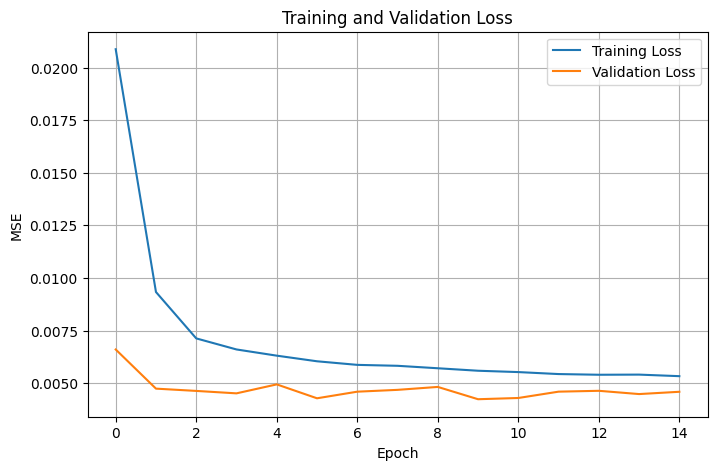

In [10]:

# Step 6: Compile and Train the Model

model.compile(optimizer='adam', loss='mse')

early_stop = EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)

history = model.fit(
    X_train, y_train,
    epochs=30,
    batch_size=32,
    validation_split=0.2,
    callbacks=[early_stop],
    verbose=1
)

# Plot training and validation loss
plt.figure(figsize=(8, 5))
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Training and Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('MSE')
plt.legend()
plt.grid(True)
plt.show()

316/316 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step
MSE:  55509.34
RMSE: 235.60
R²:   0.9692


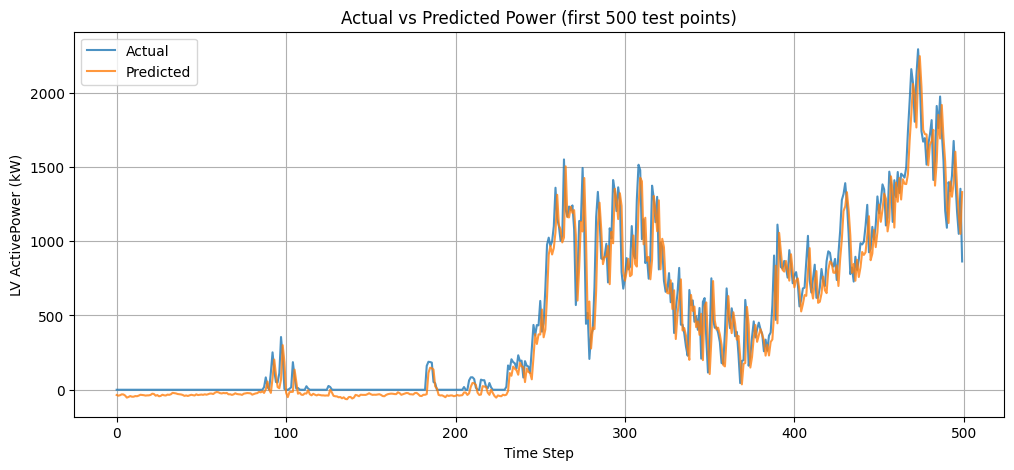

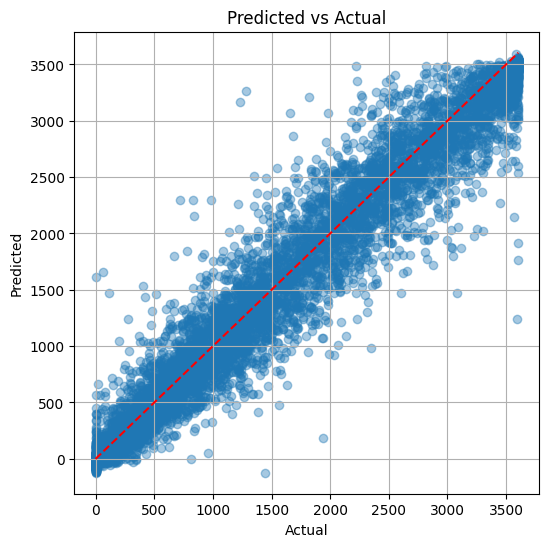

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 262ms/step


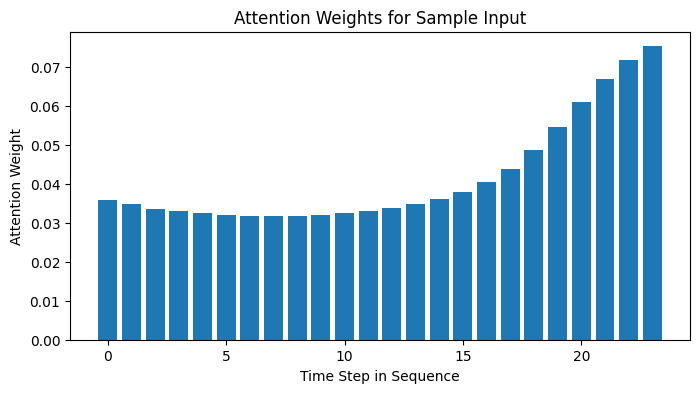

In [12]:
# Step 7: Evaluate and Visualize the Results

# Generate predictions
y_pred = model.predict(X_test).flatten()

# Inverse-transform predictions and actual values
def inverse_power(scaled_values, scaler):
    dummy = np.zeros((len(scaled_values), 3))
    dummy[:, 0] = scaled_values
    return scaler.inverse_transform(dummy)[:, 0]

y_test_inv = inverse_power(y_test, scaler)
y_pred_inv = inverse_power(y_pred, scaler)

# Evaluation metrics
mse = mean_squared_error(y_test_inv, y_pred_inv)
rmse = math.sqrt(mse)
r2 = r2_score(y_test_inv, y_pred_inv)

print(f"MSE:  {mse:.2f}")
print(f"RMSE: {rmse:.2f}")
print(f"R²:   {r2:.4f}")

# Time-series plot
plt.figure(figsize=(12, 5))
plt.plot(y_test_inv[:500], label='Actual', alpha=0.8)
plt.plot(y_pred_inv[:500], label='Predicted', alpha=0.8)
plt.title('Actual vs Predicted Power (first 500 test points)')
plt.xlabel('Time Step')
plt.ylabel('LV ActivePower (kW)')
plt.legend()
plt.grid(True)
plt.show()

# Scatter plot
plt.figure(figsize=(6, 6))
plt.scatter(y_test_inv, y_pred_inv, alpha=0.4)
plt.plot([y_test_inv.min(), y_test_inv.max()],
         [y_test_inv.min(), y_test_inv.max()], 'r--')
plt.xlabel('Actual')
plt.ylabel('Predicted')
plt.title('Predicted vs Actual')
plt.grid(True)
plt.show()

# Attention weights for a sample (without rebuilding the model)
sample = X_test[0:1]
x = sample
for layer in model.layers[1:5]:  # LSTM → Dropout → LSTM → Dropout
    x = layer(x)


attn_model = Model(inputs=input_seq, outputs=[output, attention_weights])
_, sample_attn = attn_model.predict(X_test[0:1])
attn_weights = sample_attn[0].mean(axis=-1)

plt.figure(figsize=(8, 4))
plt.bar(range(seq_length), attn_weights)
plt.title('Attention Weights for Sample Input')
plt.xlabel('Time Step in Sequence')
plt.ylabel('Attention Weight')
plt.show()